# Extracción bursátil del Perú: 2005–2025

Indicadores generales BCRP, identificación de valores SMV y verificación de acceso BVL. Se conservan los originales y se distingue registro vigente de historia de negociación.

**1. Entorno, arquitectura y archivos protegidos**

Se siguen las carpetas raw, processed y reports de los notebooks 03 y 04. Se registran hashes de todos los archivos preexistentes y se configura una caché exclusiva para esta extracción.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin
from xml.sax.saxutils import escape
from concurrent.futures import ThreadPoolExecutor
import xml.etree.ElementTree as ET
import hashlib, json, re, threading, unicodedata, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from IPython.display import display
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
assert (ROOT / "README.md").exists()
NOTEBOOK = ROOT / "notebooks/05_extraccion_bursatil.ipynb"
RAW = ROOT / "data/raw/bvl"
PROCESSED, REPORTS = ROOT / "data/processed", ROOT / "reports"
# Solo se crean archivos nuevos de esta extracción; no se modifican los anteriores.
protegidos = [ROOT / "README.md", *sorted(p for p in (ROOT / "notebooks").glob("*.ipynb") if p != NOTEBOOK),
    *sorted(p for p in (ROOT / "data").rglob("*") if p.is_file() and RAW not in p.parents),
    *sorted(p for p in REPORTS.glob("*") if p.is_file() and "bursatil" not in p.name)]
# Las salidas propias pueden existir al reproducir el notebook.
protegidos = [p for p in protegidos if not p.name.startswith(("bursatil_", "bursatiles_"))]
def hashes_protegidos(): return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos}
hashes_iniciales = hashes_protegidos()
RAW.mkdir(parents=True, exist_ok=True)
ACTUALIZAR = False  # Reutiliza incluso errores HTTP documentados; True vuelve a consultar.
BASE = "https://estadisticas.bcrp.gob.pe/estadisticas/series"
ANIOS = pd.Index(range(2005, 2026), name="anio")
SMV_FICHA = "https://mvnet.smv.gob.pe/SMV.OpenData.Web/Views/Datasets/Valores_Inscritos.aspx"
SMV_WSDL = "https://mvnet.smv.gob.pe/SMV.OpenData.wsGen/SMV.ServiciosOpenData.WCF.ServiceValores.svc/ssl?wsdl"
SMV_HTTP = "http://mvnet.smv.gob.pe/SMV.OpenData.wsGen/SMV.ServiciosOpenData.WCF.ServiceValores.svc"
GUIA = "https://www.bcrp.gob.pe/docs/Publicaciones/Guia-Metodologica/nota-semanal/Guia-Metodologica-05.pdf"
versiones = {x: metadata.version(x) for x in ["pandas", "numpy", "matplotlib", "requests", "beautifulsoup4", "nbclient", "nbformat"]}
etapas, consultas = [], []
plt.rcParams.update({"axes.grid": True, "grid.alpha": .25})
print("Python:", platform.python_version())
display(pd.Series(versiones, name="version").to_frame())
etapas.append(1)

Python: 3.12.15


,version
pandas,3.0.6
numpy,2.5.4
matplotlib,3.11.2
requests,2.34.2
beautifulsoup4,4.15.0
nbclient,0.11.0
nbformat,5.11.1


Las rutas y versiones quedan registradas. La comprobación final exigirá que los archivos anteriores y los notebooks 03 y 04 permanezcan intactos.

**2. Descargas originales y trazabilidad**

Cada consulta conserva método, URL, cuerpo público de solicitud, fecha UTC, estado HTTP y hash. La caché verifica integridad; las respuestas fallidas se registran sin convertirlas en datos económicos.

In [2]:
local = threading.local()
def sesion():
    if not hasattr(local, "session"):
        local.session = requests.Session()
        local.session.mount("https://", HTTPAdapter(max_retries=Retry(total=2, backoff_factor=.5,
            status_forcelist=[429,500,502,503,504], allowed_methods=["GET"])))
    return local.session

def descargar(url, etiqueta, metodo="GET", cuerpo=None, cabeceras=None, timeout=35):
    firma = hashlib.sha256(json.dumps([metodo, url, cuerpo, cabeceras], sort_keys=True).encode()).hexdigest()
    archivo = RAW / f"{etiqueta}_{firma[:14]}.bin"
    meta = archivo.with_suffix(".meta.json")
    if meta.exists() and not ACTUALIZAR:
        info = json.loads(meta.read_text(encoding="utf-8"))
        assert info["firma_solicitud"] == firma
        contenido = archivo.read_bytes()
        assert hashlib.sha256(contenido).hexdigest() == info["sha256"]
    else:
        info = {"metodo": metodo, "url_solicitada": url, "solicitud": cuerpo,
                "consultado_utc": datetime.now(timezone.utc).isoformat(), "firma_solicitud": firma}
        try:
            respuesta = sesion().request(metodo, url, data=cuerpo.encode("utf-8") if cuerpo else None,
                                       headers=cabeceras, timeout=(10, timeout))
            contenido = respuesta.content
            info.update(http_status=respuesta.status_code, url_final=respuesta.url,
                        content_type=respuesta.headers.get("Content-Type", ""), error=None)
        except requests.RequestException as exc:
            contenido = b""
            info.update(http_status=None, url_final=url, content_type=None, error=f"{type(exc).__name__}: {exc}")
        info.update(archivo=str(archivo.relative_to(ROOT)), sha256=hashlib.sha256(contenido).hexdigest())
        if meta.exists():
            versiones_dir = RAW / "versiones"; versiones_dir.mkdir(exist_ok=True)
            for previo in [archivo, meta]:
                digest = hashlib.sha256(previo.read_bytes()).hexdigest()
                respaldo = versiones_dir / f"{previo.stem}_{digest}{previo.suffix}"
                if not respaldo.exists(): respaldo.write_bytes(previo.read_bytes())
        archivo.write_bytes(contenido)
        meta.write_text(json.dumps(info, ensure_ascii=False, indent=2)+"\n", encoding="utf-8")
    consultas.append(info)
    return contenido, info

def json_bcrp(url, etiqueta):
    contenido, info = descargar(url, etiqueta)
    try:
        assert info["http_status"] == 200, info.get("error")
        payload = json.loads(contenido)
        assert len(payload["config"]["series"]) == 1 and payload["periods"]
        assert all(len(p["values"]) == 1 for p in payload["periods"])
        return payload
    except (AssertionError, ValueError, KeyError, TypeError, UnicodeDecodeError) as exc:
        raise RuntimeError(f"Respuesta BCRP invalida: {etiqueta} {url}") from exc
print("Caché configurada; solicitudes y respuestas se conservan en", RAW.relative_to(ROOT))
etapas.append(2)

Caché configurada; solicitudes y respuestas se conservan en data/raw/bvl


Las respuestas se preservarán sin alterar sus bytes. Un HTTP 200 no se considera suficiente: los JSON y XML deben tener la estructura esperada.

**3. Mecanismos oficiales y cambio metodológico**

Se consulta la documentación BCRP/SMV y el sitio BVL. La guía BCRP documenta el relevo de índices en mayo de 2015; se conserva la base declarada por cada serie sin empalmes propios.

In [3]:
urls_documentacion = {
    "bcrp_catalogo_mensual": BASE+"/mensuales/mercado-de-capitales",
    "bcrp_catalogo_anual": BASE+"/anuales/mercado-bursatil",
    "bcrp_api": BASE+"/ayuda/api", "bcrp_metodologia": GUIA,
    "smv_ficha_valores": SMV_FICHA, "smv_wsdl": SMV_WSDL,
    "bvl_movimientos": "https://www.bvl.com.pe/mercado/movimientos-diarios",
    "bvl_indices": "https://www.bvl.com.pe/mercado/indices",
}
documentos = {}
for etiqueta, url in urls_documentacion.items(): documentos[etiqueta] = descargar(url, etiqueta)
wsdl_bytes, wsdl_info = documentos["smv_wsdl"]
assert wsdl_info["http_status"] == 200
wsdl = ET.fromstring(wsdl_bytes)
ns = {"wsdl":"http://schemas.xmlsoap.org/wsdl/", "soap":"http://schemas.xmlsoap.org/wsdl/soap/"}
operaciones = [x.attrib["name"] for x in wsdl.findall(".//wsdl:portType/wsdl:operation", ns)]
direccion = wsdl.find(".//soap:address", ns).attrib["location"]
assert direccion == SMV_HTTP and {"consultaValoresRUC", "consultaValoresRAZONSOCIAL"}.issubset(operaciones)
for xsd in [0,2]: descargar(SMV_WSDL.replace("?wsdl", f"?xsd=xsd{xsd}"), f"smv_xsd{xsd}")
# Solo se inspeccionan recursos publicados por el propio HTML BVL; no se adivinan APIs.
html_bvl, info_bvl = documentos["bvl_movimientos"]
soup_bvl = BeautifulSoup(html_bvl, "html.parser")
js_principal = [s.get("src") for s in soup_bvl.find_all("script", src=True) if s["src"].startswith("main.")]
js_bvl = None
if js_principal:
    js_bvl = descargar(urljoin("https://www.bvl.com.pe/", js_principal[0]), "bvl_cliente_principal")
    print("Cliente BVL:", js_bvl[1]["http_status"], js_bvl[1]["content_type"])
print("Operaciones SMV publicadas:", operaciones)
print("Direccion de consulta publica publicada por SMV:", direccion)
display(pd.DataFrame([{ "recurso": k, "url": urls_documentacion[k], "http": v[1]["http_status"],
                        "content_type": v[1]["content_type"]} for k,v in documentos.items()]))
etapas.append(3)

Cliente BVL: 200 text/html; charset=UTF-8
Operaciones SMV publicadas: ['consultaValoresRUC', 'consultaValoresRAZONSOCIAL']
Direccion de consulta publica publicada por SMV: http://mvnet.smv.gob.pe/SMV.OpenData.wsGen/SMV.ServiciosOpenData.WCF.ServiceValores.svc


,recurso,url,http,content_type
0,bcrp_catalogo_mensual,https://estadisticas.bcrp.gob.pe/estadisticas/...,200,text/html; charset=UTF-8
1,bcrp_catalogo_anual,https://estadisticas.bcrp.gob.pe/estadisticas/...,200,text/html; charset=UTF-8
2,bcrp_api,https://estadisticas.bcrp.gob.pe/estadisticas/...,200,text/html; charset=UTF-8
3,bcrp_metodologia,https://www.bcrp.gob.pe/docs/Publicaciones/Gui...,200,text/html
4,smv_ficha_valores,https://mvnet.smv.gob.pe/SMV.OpenData.Web/View...,200,text/html; charset=utf-8
5,smv_wsdl,https://mvnet.smv.gob.pe/SMV.OpenData.wsGen/SM...,200,text/xml; charset=UTF-8
6,bvl_movimientos,https://www.bvl.com.pe/mercado/movimientos-dia...,200,text/html; charset=UTF-8
7,bvl_indices,https://www.bvl.com.pe/mercado/indices,200,text/html; charset=UTF-8


La documentación distingue series temporales BCRP, consultas de valores inscritos SMV y la aplicación web BVL. La disponibilidad de una página BVL no demuestra que exista una API pública de históricos.

Fuentes: [guía metodológica BCRP](https://www.bcrp.gob.pe/docs/Publicaciones/Guia-Metodologica/nota-semanal/Guia-Metodologica-05.pdf), [ficha SMV](https://mvnet.smv.gob.pe/SMV.OpenData.Web/Views/Datasets/Valores_Inscritos.aspx) y [sitio BVL](https://www.bvl.com.pe/mercado/movimientos-diarios).

**4. Series generales seleccionadas y consulta BCRP**

Se solicitan índices de cierre, renta variable, negociación en acciones y capitalización. Se incorpora diciembre de 2004 solo como base del rendimiento de 2005; las cotizaciones individuales permanecen separadas.

In [4]:
series = pd.DataFrame([
    ["PN01142MM","M","2004-12","2025-12","indice_general_cierre","Indice General BVL, base 31/12/91=100","puntos","BVL"],
    ["PN01159MM","M","2005-1","2025-12","monto_renta_variable","Renta variable negociada mensual","millones PEN","BVL, CAVALI"],
    ["PM06338MA","A","2004","2025","indice_general_anual","Indice General BVL anual, base 31/12/91=100","puntos","BVL, CAVALI"],
    ["PM06345MA","A","2005","2025","monto_renta_variable_anual","Renta variable negociada anual","millones PEN","BVL, CAVALI"],
    ["PM06348MA","A","2005","2025","capitalizacion_anual","Capitalizacion bursatil anual","millones PEN","BVL, CAVALI"],
    ["PD04694MD","D","2005-1-1","2025-12-31","variacion_diaria_indice","Variacion diaria del Indice General BVL","porcentaje","BCRP"],
    ["PD04696MD","D","2005-1-1","2025-12-31","monto_acciones_diario","Monto negociado en acciones; etiqueta oficial promedio diario","millones PEN","BCRP"],
], columns=["codigo","frecuencia","inicio","fin","variable","descripcion","unidad","fuente_original"])
series["url_api"] = series.apply(lambda s:f"{BASE}/api/{s.codigo}/json/{s.inicio}/{s.fin}/esp",axis=1)
series["url_ficha"] = series.apply(lambda s:f"{BASE}/{'mensuales' if s.frecuencia=='M' else 'anuales' if s.frecuencia=='A' else 'diarias'}/resultados/{s.codigo}/html",axis=1)
respuestas = {}
for s in series.itertuples(index=False): respuestas[s.codigo] = json_bcrp(s.url_api, s.codigo)
series["nombre_api"] = series.codigo.map(lambda c: respuestas[c]["config"]["series"][0]["name"])
display(series[["codigo","frecuencia","descripcion","nombre_api","unidad"]])
etapas.append(4)

,codigo,frecuencia,descripcion,nombre_api,unidad
0,PN01142MM,M,"Indice General BVL, base 31/12/91=100",Bolsa de Valores de Lima - Índices Bursátiles ...,puntos
1,PN01159MM,M,Renta variable negociada mensual,Bolsa de Valores de Lima - Montos Negociados e...,millones PEN
2,PM06338MA,A,"Indice General BVL anual, base 31/12/91=100",Mercado bursátil - Principales Índices Bursáti...,puntos
3,PM06345MA,A,Renta variable negociada anual,Mercado bursátil - Montos Negociados Anuales -...,millones PEN
4,PM06348MA,A,Capitalizacion bursatil anual,Mercado bursátil - Capitalización Bursátil (mi...,millones PEN
5,PD04694MD,D,Variacion diaria del Indice General BVL,Indicadores bursátiles - Índice General Bursát...,porcentaje
6,PD04696MD,D,Monto negociado en acciones; etiqueta oficial ...,Indicadores bursátiles - Monto negociado en ac...,millones PEN


Los nombres devueltos por BCRP permiten comprobar alcance y unidades. Renta variable mensual/anual y negociación diaria de acciones son conceptos separados; no se igualan sus totales automáticamente.

**5. Periodos, faltantes, duplicados y calendario**

Se convierten fechas y números sin imputar n.d. Los días laborables sin valor se reportan sin tratarlos automáticamente como sesiones perdidas: falta un calendario histórico oficial de negociación.

In [5]:
MESES = dict(zip(["ene","feb","mar","abr","may","jun","jul","ago","sep","oct","nov","dic"],range(1,13)))
MESES.update(set=9, sept=9)
def fecha_bcrp(texto, frecuencia):
    if frecuencia == "A": return pd.Timestamp(int(texto),1,1)
    if frecuencia == "M":
        m = re.fullmatch(r"([A-Za-z]+)\.(\d{4})", texto); assert m, texto
        return pd.Timestamp(int(m[2]),MESES[m[1].lower()],1)
    m = re.fullmatch(r"(\d{2})\.([A-Za-z]+)\.(\d{2,4})", texto); assert m, texto
    year = int(m[3]); year = year + 2000 if year < 100 else year
    return pd.Timestamp(year,MESES[m[2].lower()],int(m[1]))
tablas, controles, ausencias = {}, [], []
for s in series.itertuples(index=False):
    rows = respuestas[s.codigo]["periods"]
    t = pd.DataFrame({"periodo_original":[p["name"] for p in rows],"valor_original":[p["values"][0] for p in rows]})
    t["fecha"] = t.periodo_original.map(lambda x:fecha_bcrp(x,s.frecuencia))
    texto = t.valor_original.astype("string").str.strip()
    t["valor"] = pd.to_numeric(texto.mask(texto.str.lower().isin(["n.d.","n.d","", "null", "nan"])),errors="raise").astype(float)
    assert not t.fecha.duplicated().any(), s.codigo
    assert np.isfinite(t.loc[t.valor.notna(),"valor"]).all()
    t = t.sort_values("fecha").reset_index(drop=True); tablas[s.codigo] = t
    inicio = pd.Timestamp(s.inicio+"-01" if s.frecuencia=="M" else s.inicio+"-01-01" if s.frecuencia=="A" else s.inicio)
    fin = pd.Timestamp(s.fin+"-01" if s.frecuencia=="M" else s.fin+"-01-01" if s.frecuencia=="A" else s.fin)
    calendario = pd.date_range(inicio,fin,freq={"M":"MS","A":"YS","D":"B"}[s.frecuencia])
    assert t.fecha.between(inicio,fin).all()
    faltan = calendario.difference(t.fecha)
    controles.append({"codigo":s.codigo,"registros":len(t),"faltantes_valor":int(t.valor.isna().sum()),
        "periodos_sin_fila":len(faltan),"duplicados":int(t.fecha.duplicated().sum()),"frecuencia":s.frecuencia,
        "inicio_observado":t.fecha.min().date().isoformat(),"fin_observado":t.fecha.max().date().isoformat()})
    for f in faltan: ausencias.append({"codigo":s.codigo,"fecha":f,"estado":"SIN_FILA; calendario sin feriados verificados" if s.frecuencia=="D" else "SIN_FILA"})
    for f in t.loc[t.valor.isna(),"fecha"]: ausencias.append({"codigo":s.codigo,"fecha":f,"estado":"n.d. original; no imputado"})
calidad = pd.DataFrame(controles)
periodos_faltantes = pd.DataFrame(ausencias,columns=["codigo","fecha","estado"])
mensual = pd.concat([tablas[s.codigo].set_index("fecha").valor.rename(s.variable)
                    for s in series.itertuples(index=False) if s.frecuencia=="M"],axis=1)
diario = pd.concat([tablas[s.codigo].set_index("fecha").valor.rename(s.variable)
                    for s in series.itertuples(index=False) if s.frecuencia=="D"],axis=1)
assert mensual.indice_general_cierre.dropna().gt(0).all()
assert diario.variacion_diaria_indice.dropna().gt(-100).all()
diario["monto_acciones_negativo"] = diario.monto_acciones_diario.lt(0)
anomalias_montos = diario.loc[diario.monto_acciones_negativo, ["monto_acciones_diario"]].reset_index()
print("Montos diarios negativos de origen:", len(anomalias_montos), "— conservados y excluyen la suma anual del año afectado.")
display(anomalias_montos)
assert mensual.monto_renta_variable.dropna().ge(0).all()
display(calidad)
etapas.append(5)

Montos diarios negativos de origen: 3 — conservados y excluyen la suma anual del año afectado.


,fecha,monto_acciones_diario
0,2016-05-05,-0.248453
1,2016-05-06,-0.320838
2,2016-05-09,-1.590270


,codigo,registros,faltantes_valor,periodos_sin_fila,duplicados,frecuencia,inicio_observado,fin_observado
0,PN01142MM,253,0,0,0,M,2004-12-01,2025-12-01
1,PN01159MM,252,0,0,0,M,2005-01-01,2025-12-01
2,PM06338MA,22,0,0,0,A,2004-01-01,2025-01-01
3,PM06345MA,21,0,0,0,A,2005-01-01,2025-01-01
4,PM06348MA,21,0,0,0,A,2005-01-01,2025-01-01
5,PD04694MD,5478,199,0,0,D,2005-01-03,2025-12-31
6,PD04696MD,5478,186,0,0,D,2005-01-03,2025-12-31


Los n.d. se conservan como ausencias de publicación, sin inventar rentabilidades nulas. La tabla de periodos faltantes separa registros ausentes de valores n.d.; la cobertura diaria no equivale a un calendario oficial de sesiones.

**6. Rentabilidad anual, volatilidad y negociación**

Se calcula R anual = 100 × (I diciembre / I diciembre previo − 1) y volatilidad = 100 × std(log(1+r), ddof=1) × √252. La volatilidad diaria exige ≥200 observaciones y presencia en 12 meses, sin certificar sesiones completas.

In [6]:
mensual["retorno_mensual_pct"] = mensual.indice_general_cierre.pct_change(fill_method=None).mul(100)
indice_dic = mensual.loc[mensual.index.month == 12,"indice_general_cierre"]
retorno_dic = indice_dic.pct_change(fill_method=None).mul(100)
anual = pd.DataFrame(index=ANIOS)
anual["indice_general_cierre"] = pd.Series(indice_dic.to_numpy(),index=indice_dic.index.year)
anual["rentabilidad_indice_anual_pct"] = pd.Series(retorno_dic.to_numpy(),index=retorno_dic.index.year)
for codigo, columna in [("PM06338MA","indice_cierre_publicado_anual"),("PM06345MA","monto_renta_variable_anual_millones_pen"),("PM06348MA","capitalizacion_millones_pen")]:
    x = tablas[codigo].set_index("fecha").valor
    anual[columna] = pd.Series(x.to_numpy(),index=x.index.year)
x = mensual.loc["2005":"2025","monto_renta_variable"]
anual["monto_renta_variable_suma_meses_millones_pen"] = x.groupby(x.index.year).sum(min_count=12)
anual["diferencia_renta_variable_millones_pen"] = anual.monto_renta_variable_suma_meses_millones_pen - anual.monto_renta_variable_anual_millones_pen
cobertura_mercado = []
for anio in ANIOS:
    x = diario.loc[str(anio)]
    r = x.variacion_diaria_indice.dropna().div(100)
    nobs, nmeses = len(r), r.index.month.nunique()
    anual.loc[anio,"n_retornos_diarios"] = nobs
    anual.loc[anio,"n_meses_con_retornos"] = nmeses
    anual.loc[anio,"volatilidad_diaria_anualizada_pct"] = np.log1p(r).std(ddof=1)*np.sqrt(252)*100 if nobs>=200 and nmeses==12 else np.nan
    anual.loc[anio,"retorno_compuesto_observaciones_diarias_pct"] = np.expm1(np.log1p(r).sum())*100 if nobs>=200 and nmeses==12 else np.nan
    anual.loc[anio,"monto_acciones_suma_observaciones_diarias_millones_pen"] = x.monto_acciones_diario.sum(min_count=200) if not x.monto_acciones_negativo.any() else np.nan
    cobertura_mercado.append({"anio":int(anio),"filas_diarias":len(x),"retornos_validos":nobs,"retornos_nd":int(x.variacion_diaria_indice.isna().sum()),
        "montos_validos":int((x.monto_acciones_diario.notna() & ~x.monto_acciones_negativo).sum()), "montos_negativos":int(x.monto_acciones_negativo.sum()),"dias_monto_positivo":int(x.monto_acciones_diario.gt(0).sum()),
        "meses_indice":int(mensual.loc[str(anio),"indice_general_cierre"].notna().sum()),
        "calendario_sesiones":"NO_VERIFICADO"})
anual["diferencia_rentabilidad_pp"] = anual.retorno_compuesto_observaciones_diarias_pct - anual.rentabilidad_indice_anual_pct
anual["transicion_metodologica_2015"] = anual.index == 2015
anual["regimen_documentado"] = np.where(anual.index<2015,"IGBVL previo",np.where(anual.index==2015,"Transicion mayo 2015","S&P/BVL Peru General"))
anual["diferencia_diario_mensual_revisar"] = anual.diferencia_rentabilidad_pp.abs().gt(.1)
cobertura_mercado = pd.DataFrame(cobertura_mercado)
display(anual.round(4))
display(cobertura_mercado)
etapas.append(6)

,indice_general_cierre,rentabilidad_indice_anual_pct,indice_cierre_publicado_anual,monto_renta_variable_anual_millones_pen,capitalizacion_millones_pen,monto_renta_variable_suma_meses_millones_pen,diferencia_renta_variable_millones_pen,n_retornos_diarios,n_meses_con_retornos,volatilidad_diaria_anualizada_pct,retorno_compuesto_observaciones_diarias_pct,monto_acciones_suma_observaciones_diarias_millones_pen,diferencia_rentabilidad_pp,transicion_metodologica_2015,regimen_documentado,diferencia_diario_mensual_revisar
anio,,,,,,,,,,,,,,,,
2005,4802.25,29.4271,4802.25,8754.4300,124061.5200,8754.4300,0.0000,251.0,12.0,16.1787,29.4271,6785.8410,-0.0000,False,IGBVL previo,False
2006,12884.20,168.2951,12884.20,17916.4400,192364.0000,17916.4400,0.0000,251.0,12.0,23.9027,167.2225,14683.8653,-1.0725,False,IGBVL previo,True
2007,17524.79,36.0177,17524.79,35196.8800,324118.0400,35197.4700,0.5900,251.0,12.0,28.0414,35.9552,28489.3140,-0.0625,False,IGBVL previo,False
2008,7048.67,-59.7789,7031.81,18655.1900,179163.0339,18655.4200,0.2300,248.0,12.0,46.0531,-59.7789,14240.4322,-0.0000,False,IGBVL previo,False
2009,14167.20,100.9911,14167.20,13706.4190,310116.4221,13706.4190,0.0000,249.0,12.0,28.8694,100.9911,11219.8580,0.0000,False,IGBVL previo,False
2010,23374.57,64.9908,23374.57,16873.0390,451796.2200,16873.0390,0.0000,251.0,12.0,18.3807,64.9908,13673.4621,-0.0000,False,IGBVL previo,False
2011,19473.71,-16.6885,19473.71,19763.6860,327823.2200,19763.6860,0.0000,252.0,12.0,33.6794,-16.6885,16691.1411,0.0000,False,IGBVL previo,False
2012,20629.35,5.9344,20629.35,18533.6600,391180.6900,18533.6600,0.0000,251.0,12.0,13.1441,5.9344,15273.3679,-0.0000,False,IGBVL previo,False
2013,15753.65,-23.6348,15753.65,13511.3222,337226.2100,13511.3222,0.0000,250.0,12.0,18.3290,-24.4203,10939.9273,-0.7855,False,IGBVL previo,True


,anio,filas_diarias,retornos_validos,retornos_nd,montos_validos,montos_negativos,dias_monto_positivo,meses_indice,calendario_sesiones
0,2005,260,251,9,251,0,251,12,NO_VERIFICADO
1,2006,260,251,9,251,0,251,12,NO_VERIFICADO
2,2007,261,251,10,250,0,250,12,NO_VERIFICADO
3,2008,262,248,14,248,0,248,12,NO_VERIFICADO
4,2009,261,249,12,250,0,250,12,NO_VERIFICADO
5,2010,261,251,10,251,0,251,12,NO_VERIFICADO
6,2011,260,252,8,252,0,252,12,NO_VERIFICADO
7,2012,261,251,10,251,0,251,12,NO_VERIFICADO
8,2013,261,250,11,250,0,250,12,NO_VERIFICADO
9,2014,261,249,12,249,0,249,12,NO_VERIFICADO


Las rentabilidades corresponden al índice publicado en soles, no a una cartera individual ni a retornos en dólares. La volatilidad usa observaciones disponibles; 2015 y las discrepancias entre frecuencias quedan señaladas, sin reajustar las series.

**7. Empresas e identificadores del panel financiero**

Se conservan las 336 empresas y todas sus denominaciones históricas. Los RUC anómalos no se corrigen; las consultas por nombre no autorizan una correspondencia aproximada con valores.

In [7]:
fin = pd.read_csv(ROOT/"data/processed/features_financieras.csv",dtype={"RPJ":"string","RUC":"string"},float_precision="round_trip")
assert fin.shape==(4221,57) and fin.RPJ.nunique()==336
assert fin.groupby("RPJ").RUC.nunique(dropna=False).eq(1).all()
empresas = fin.sort_values(["RPJ","Ejercicio"]).groupby("RPJ",sort=True).agg(
    RUC=("RUC","first"),razon_social=("NombreEmpresa","last"),anio_financiero_inicio=("Ejercicio","min"),anio_financiero_fin=("Ejercicio","max")).reset_index()
alias = fin.groupby("RPJ").NombreEmpresa.agg(lambda x:list(dict.fromkeys(x.dropna().tolist()))).to_dict()
def normalizar_nombre(x):
    x = unicodedata.normalize("NFKD",str(x)).encode("ascii","ignore").decode().upper()
    return re.sub(r"[^A-Z0-9]","",x)
empresas["ruc_formato_11"] = empresas.RUC.str.fullmatch(r"\d{11}",na=False)
print("Empresas:",len(empresas),"| RUC distintos:",empresas.RUC.nunique(),"| RUC sin formato de 11 digitos:",int((~empresas.ruc_formato_11).sum()))
display(empresas.head())
etapas.append(7)

Empresas: 336 | RUC distintos: 331 | RUC sin formato de 11 digitos: 6


,RPJ,RUC,razon_social,anio_financiero_inicio,anio_financiero_fin,ruc_formato_11
0,000355,20100082391,COSAPI S.A.,2015,2024,True
1,000432,20100070970,SUPERMERCADOS PERUANOS S.A.,2005,2018,True
2,000683,20100195080,CONSORCIO INDUSTRIAL DE AREQUIPA SA,2005,2023,True
3,000717,20100154308,SAN FERNANDO S.A.,2006,2015,True
4,000981,20100193117,YARA PERU S.R.L.,2007,2011,True


Los RUC se mantienen como texto y cada empresa conserva su RPJ. La ausencia de un RUC válido se registra como limitación de identificación, sin excluir empresas.

**8. Consulta de valores inscritos por RUC y razón social**

Se usa la operación y dirección publicadas por el WSDL, con hasta tres consultas simultáneas. Si un RUC no permite resolver la empresa, se consulta la razón social exacta; los fallos no se interpretan como ausencia histórica de acciones.

In [8]:
campos_valores = ["CodigoISIN","Cotizacion","DenominacionValor","FechaInscripcion","FechaUltCot","Moneda","MontoInscrito","NemonicoValor","RazonSocial","ResolucionInscripcion","TipoValor"]
def consulta_smv(empresa, por_nombre=False):
    op = "consultaValoresRAZONSOCIAL" if por_nombre else "consultaValoresRUC"
    parametro = "pstrRAZONSOCIAL" if por_nombre else "pstrRUC"
    valor = empresa.razon_social if por_nombre else empresa.RUC
    cuerpo = f'<s:Envelope xmlns:s="http://schemas.xmlsoap.org/soap/envelope/"><s:Body><{op} xmlns="http://tempuri.org/"><{parametro}>{escape(str(valor))}</{parametro}></{op}></s:Body></s:Envelope>'
    datos, info = descargar(direccion,f"smv_{empresa.RPJ}_{'nombre' if por_nombre else 'ruc'}","POST",cuerpo,
                           {"Content-Type":"text/xml; charset=utf-8","SOAPAction":f'"http://tempuri.org/IServiceValores/{op}"'},timeout=30)
    estado = {"RPJ":empresa.RPJ,"consulta_por":"razon_social" if por_nombre else "RUC", "valor_consultado":valor,
              "http_status":info["http_status"],"archivo":info["archivo"],"filas":0,"codigo_error":None,"mensaje_error":None,"estado":"ERROR_ACCESO"}
    filas=[]
    if info["http_status"]==200:
        try:
            root = ET.fromstring(datos)
            nodos = root.findall(".//{*}ValorObtenidoBE")
            fault = root.find(".//{*}Fault")
            if fault is not None: raise ValueError("SOAP Fault")
            resultado = root.find(f".//{{*}}{op}Result")
            if resultado is None: raise ValueError("Resultado SOAP no encontrado")
            texto = lambda tag: resultado.findtext(f"{{*}}{tag}")
            estado.update(codigo_error=texto("CodigoError"),mensaje_error=texto("MensajeError"),filas=len(nodos),
                          estado="VALORES_RECIBIDOS" if nodos else "SIN_RESULTADO_ACTUAL")
            for nodo in nodos:
                row={k:nodo.findtext(f"{{*}}{k}") or None for k in campos_valores}
                row.update(RPJ_consultado=empresa.RPJ,RUC_consultado=empresa.RUC,consulta_por=estado["consulta_por"],archivo_original=info["archivo"],consultado_utc=info["consultado_utc"])
                filas.append(row)
        except (ET.ParseError,ValueError) as exc: estado.update(estado="ERROR_RESPUESTA",mensaje_error=str(exc))
    return filas,estado

def resolver_empresa(e):
    filas, estados = [], []
    if e.ruc_formato_11:
        f,s = consulta_smv(e);filas.extend(f);estados.append(s)
    if not filas:
        f,s = consulta_smv(e,True);filas.extend(f);estados.append(s)
    return filas,estados
filas_smv, estados_smv = [], []
with ThreadPoolExecutor(max_workers=3) as executor:
    for i,(f,s) in enumerate(executor.map(resolver_empresa,empresas.itertuples(index=False)),1):
        filas_smv.extend(f);estados_smv.extend(s)
        if i%40==0 or i==len(empresas): print(f"Empresas consultadas: {i}/{len(empresas)}",flush=True)
registro = pd.DataFrame(filas_smv,columns=[*campos_valores,"RPJ_consultado","RUC_consultado","consulta_por","archivo_original","consultado_utc"])
estados_consultas = pd.DataFrame(estados_smv)
assert set(estados_consultas.RPJ)==set(empresas.RPJ)
display(estados_consultas.groupby(["consulta_por","estado"],dropna=False).size().rename("consultas").to_frame())
print("Filas de valores recibidas:",len(registro))
etapas.append(8)

Empresas consultadas: 40/336


Empresas consultadas: 80/336


Empresas consultadas: 120/336


Empresas consultadas: 160/336


Empresas consultadas: 200/336


...

Empresas consultadas: 280/336


Empresas consultadas: 320/336


Empresas consultadas: 336/336


consultas
consulta_por estado                         
RUC          SIN_RESULTADO_ACTUAL        176
             VALORES_RECIBIDOS           154
razon_social SIN_RESULTADO_ACTUAL        175
             VALORES_RECIBIDOS             7

Filas de valores recibidas: 1032


El registro es una instantánea consultada hoy, no un catálogo histórico de empresas cotizadas entre 2005 y 2025. Un resultado vacío o un error del servicio no demuestra que una empresa nunca haya cotizado.

**9. Correspondencia, clases de valores y calidad de identificadores**

Se exige coincidencia exacta normalizada con alguna razón social del panel y se conserva el criterio RUC/nombre de consulta. Se verifican ISIN y clases de acciones sin completar códigos truncados ni fusionar acciones comunes y de inversión.

In [9]:
def isin_valido(valor):
    if not isinstance(valor,str) or not re.fullmatch(r"[A-Z]{2}[A-Z0-9]{9}[0-9]",valor): return False
    digitos="".join(str(ord(c)-55) if c.isalpha() else c for c in valor)
    total=0
    for i,d in enumerate(reversed(digitos)):
        z=int(d)*(2 if i%2 else 1); total+=z//10+z%10
    return total%10==0
registro["nombre_verificado"] = [normalizar_nombre(x.RazonSocial) in {normalizar_nombre(a) for a in alias[x.RPJ_consultado]} for x in registro.itertuples(index=False)]
registro["metodo_identificacion"] = np.where(registro.consulta_por.eq("RUC"),"RUC consultado + razon social exacta","Solo razon social exacta; RUC no devuelto")
registro["correspondencia_emisor_verificada"] = registro.nombre_verificado & registro.consulta_por.eq("RUC")
registro["isin_valido"] = registro.CodigoISIN.map(isin_valido)
registro["es_accion"] = registro.TipoValor.fillna("").str.upper().str.contains(r"ACCION",regex=True)
registro["accion_emisor_verificado"] = registro.es_accion & registro.correspondencia_emisor_verificada
registro["tipo_instrumento"] = registro.TipoValor.fillna("NO_INFORMADO")
registro["nemonico_informado"] = registro.NemonicoValor.notna()
registro["fecha_ultima_cotizacion"] = pd.to_datetime(registro.FechaUltCot,format="%d/%m/%Y",errors="coerce")
registro["cotizacion_original_numerica"] = pd.to_numeric(registro.Cotizacion,errors="coerce")
registro["cotizacion_fuera_periodo"] = registro.fecha_ultima_cotizacion.notna() & ~registro.fecha_ultima_cotizacion.between("2005-01-01","2025-12-31")
registro["moneda_iso_documentada"] = registro.Moneda.map({"SOLES":"PEN","DOLARES":"USD"})
registro["moneda_sin_equivalencia_verificada"] = registro.moneda_iso_documentada.isna()
assert registro.moneda_iso_documentada.dropna().isin(["PEN","USD"]).all()
calidad_monedas = registro.groupby(["Moneda","moneda_iso_documentada"],dropna=False).size().rename("filas").reset_index()
print("Monedas recibidas (sin conversion de precios):")
display(calidad_monedas)
registro["identidad_instrumento_completa"] = registro.correspondencia_emisor_verificada & registro.isin_valido & registro.nemonico_informado
# Filas recibidas se conservan; la tabla de instrumentos agrupa sin elegir montos o precios contradictorios.
claves=["RPJ_consultado","NemonicoValor","CodigoISIN","TipoValor","Moneda"]
instrumentos = registro.groupby(claves,dropna=False).agg(
    filas_fuente=("archivo_original","size"),emisor_verificado=("correspondencia_emisor_verificada","all"),
    isin_valido=("isin_valido","all"),es_accion=("es_accion","all"),identidad_completa=("identidad_instrumento_completa","all"),
    montos_inscritos_distintos=("MontoInscrito",lambda x:x.nunique(dropna=False)),
    precios_distintos=("Cotizacion",lambda x:x.nunique(dropna=False)),ultima_cotizacion=("fecha_ultima_cotizacion","max")).reset_index()
instrumentos["calidad_negociacion_historica"] = "NO_EVALUABLE_SIN_HISTORICO"
instrumentos["n_observaciones_historicas"] = pd.NA
instrumentos["cotizacion_asignada_al_panel"] = False
print("Filas exactamente repetidas:",int(registro.duplicated([*campos_valores,"RPJ_consultado"]).sum()))
print("ISIN no validos en filas recibidas:",int((~registro.isin_valido).sum()))
display(instrumentos.groupby(["TipoValor","Moneda"],dropna=False).size().rename("instrumentos_segun_registro").to_frame())
display(instrumentos.head(10))
etapas.append(9)

Monedas recibidas (sin conversion de precios):


,Moneda,moneda_iso_documentada,filas
0,DOLARES,USD,231
1,SOLES,PEN,801


Filas exactamente repetidas: 0
ISIN no validos en filas recibidas: 1032


instrumentos_segun_registro
TipoValor                                          Moneda                              
ACCIONES DE CAPITAL                                DOLARES                            2
                                                   SOLES                            138
ACCIONES DE CAPITAL PREF. S/D VOTO                 SOLES                             11
ACCIONES DE CAPITAL PREFERENCIAL                   SOLES                              2
ACCIONES DE INVERSION                              SOLES                             36
BONOS CORPORATIVOS                                 DOLARES                            6
                                                   SOLES                              2
BONOS DE ARRENDAMIENTO FINANCIERO                  DOLARES                           39
BONOS HIPOTECARIOS                                 DOLARES                           13
BONOS SUBORDINADOS                                 DOLARES                           41
                                                   SOLES                             32
CERTIFICADOS DE DEPOSITOS                          SOLES                             76
CERTIFICADOS DE SUSCRIPCION PREFERENTE             SOLES                              2
PROGRAMA DE BONOS CORPORATIVOS                     DOLARES                           52
                                                   SOLES                            299
PROGRAMA DE BONOS DE ARRENDAMIENTO FINANCIERO      DOLARES                           40
                                                   SOLES                             13
PROGRAMA DE EMISION DE INSTRUMENTOS FINANCIEROS DE DOLARES                           16
                                                   SOLES                             26
SIN DESCRIPCION                                    DOLARES                            2
VALORES MIENM                                      DOLARES                            1

,RPJ_consultado,NemonicoValor,CodigoISIN,TipoValor,Moneda,filas_fuente,emisor_verificado,isin_valido,es_accion,identidad_completa,montos_inscritos_distintos,precios_distintos,ultima_cotizacion,calidad_negociacion_historica,n_observaciones_historicas,cotizacion_asignada_al_panel
0,001152,FUTURAC1,73630100,ACCIONES DE CAPITAL,SOLES,2,True,False,True,False,2,1,2024-06-28,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
1,001152,FUTURAI1,73630500,ACCIONES DE INVERSION,SOLES,2,True,False,True,False,2,1,2026-07-06,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
2,002597,MINCORC1,61630100,ACCIONES DE CAPITAL,SOLES,2,True,False,True,False,2,1,2026-10-06,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
3,002597,MINCORI1,61630500,ACCIONES DE INVERSION,SOLES,2,True,False,True,False,2,1,2026-10-16,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
4,002766,RELAP2CP4A,52105V22,PROGRAMA DE EMISION DE INSTRUMENTOS FINANCIERO...,DOLARES,1,True,False,False,False,1,1,NaT,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
5,002766,RELAP3BC1A,52105M01,PROGRAMA DE BONOS CORPORATIVOS,DOLARES,1,True,False,False,False,1,1,NaT,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
6,002766,RELAP3BC1B,52105M02,PROGRAMA DE BONOS CORPORATIVOS,DOLARES,1,True,False,False,False,1,1,NaT,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
7,002766,RELAP3BC4A,52105M03,PROGRAMA DE BONOS CORPORATIVOS,DOLARES,1,True,False,False,False,1,1,NaT,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
8,002766,RELAP5BC1A,52105M04,PROGRAMA DE BONOS CORPORATIVOS,DOLARES,1,True,False,False,False,1,1,NaT,NO_EVALUABLE_SIN_HISTORICO,<NA>,False
9,002766,RELAPAC1,52105110,ACCIONES DE CAPITAL,SOLES,1,True,False,True,False,1,1,2021-10-15,NO_EVALUABLE_SIN_HISTORICO,<NA>,False


Los códigos inválidos y los montos contradictorios permanecen visibles. El nemónico identifica un valor reportado, pero no sustituye un ISIN válido ni prueba una historia de precios ajustados; no se asignan cotizaciones al panel.

**10. Cobertura empresarial y periodos individuales no obtenidos**

Se distinguen emisor identificado, valor registrado y serie histórica descargada. Se conserva el universo completo; sin series individuales no se concluye ausencia de cotización ni se evalúa iliquidez.

In [10]:
resumen_registro = registro.groupby("RPJ_consultado").agg(
    filas_registro_smv=("archivo_original","size"),emisor_identificado=("correspondencia_emisor_verificada","any"),
    accion_registrada=("accion_emisor_verificado","any"),instrumento_identidad_completa=("identidad_instrumento_completa","any"),
    ultima_cotizacion_informada=("fecha_ultima_cotizacion","max"))
empresas_cobertura = empresas.merge(resumen_registro,left_on="RPJ",right_index=True,how="left",validate="one_to_one")
empresas_cobertura["filas_registro_smv"] = empresas_cobertura.filas_registro_smv.fillna(0).astype(int)
for x in ["emisor_identificado","accion_registrada","instrumento_identidad_completa"]:
    empresas_cobertura[x] = empresas_cobertura[x].fillna(False).astype(bool)
empresas_cobertura["estado_identificacion"] = np.where(empresas_cobertura.emisor_identificado,
    "EMISOR_VERIFICADO_RUC_Y_NOMBRE",np.where(empresas_cobertura.filas_registro_smv.gt(0),
    "RESULTADO_CON_IDENTIDAD_PENDIENTE","SIN_RESULTADO_ACTUAL; historia no verificada"))
empresas_cobertura["estado_historico_individual"] = "NO_OBTENIDO; disponibilidad real NO_VERIFICADA"
empresas_cobertura["calidad_negociacion_historica"] = "NO_EVALUABLE"
assert len(empresas_cobertura)==336 and empresas_cobertura.RPJ.is_unique
cobertura_empresas_anual = pd.MultiIndex.from_product([empresas.RPJ,ANIOS],names=["RPJ","anio"]).to_frame(index=False)
cobertura_empresas_anual["observaciones_historicas_descargadas"] = 0
cobertura_empresas_anual["estado"] = "SIN_SERIE_OBTENIDA; no implica ausencia de negociacion"
cobertura_empresas_anual["negociacion_insuficiente"] = pd.NA
cobertura_instrumentos_anual = instrumentos[claves].merge(pd.DataFrame({"anio":ANIOS}),how="cross")
cobertura_instrumentos_anual["estado"] = "HISTORICO_NO_OBTENIDO"
cobertura_instrumentos_anual["negociacion_insuficiente"] = pd.NA
cobertura_anual_individual = cobertura_empresas_anual.groupby("anio").agg(empresas_conservadas=("RPJ","nunique"),observaciones_descargadas=("observaciones_historicas_descargadas","sum"))
display(pd.Series({"empresas_panel":len(empresas),"emisores_verificados_smv":int(empresas_cobertura.emisor_identificado.sum()),
    "empresas_con_valores_en_respuesta":int(empresas_cobertura.filas_registro_smv.gt(0).sum()),
    "empresas_con_historico_individual_descargado":0,"empresas_con_historia_no_verificada":len(empresas)}).rename("conteo").to_frame())
display(cobertura_anual_individual)
etapas.append(10)

,conteo
empresas_panel,336
emisores_verificados_smv,154
empresas_con_valores_en_respuesta,161
empresas_con_historico_individual_descargado,0
empresas_con_historia_no_verificada,336


,empresas_conservadas,observaciones_descargadas
anio,,
2005,336,0
2006,336,0
2007,336,0
2008,336,0
2009,336,0
2010,336,0
2011,336,0
2012,336,0
2013,336,0


Las tablas conservan 336 empresas y los 21 años de análisis. Los ceros cuentan únicamente observaciones descargadas; no son precios, volúmenes ni evidencia de ausencia de negociación. La negociación insuficiente queda no evaluable.

**11. Fuentes, restricciones y disponibilidad temporal**

Se documenta qué mecanismo permitió obtener cada dato y qué quedó sin verificar. Los indicadores anuales solo pueden usarse tras su publicación; las últimas cotizaciones y el registro actual no reconstruyen información histórica disponible.

In [11]:
cliente_bvl_html = bool(js_bvl and b"<html" in js_bvl[0][:500].lower())
fuentes = pd.DataFrame([
    {"fuente":"BCRP","mecanismo":"API GET JSON","acceso":"VERIFICADO","cobertura":"2005–2025; base diciembre 2004 para indice","restriccion":"n.d. diarios, calendario de sesiones no certificado; relevo metodologico mayo 2015","url":BASE+"/ayuda/api"},
    {"fuente":"SMV","mecanismo":"WSDL/SOAP por RUC o razon social","acceso":"CONSULTADO","cobertura":"Instantanea; no historico diario","restriccion":"Direccion HTTP publica; codigos ISIN y montos recibidos pueden ser inconsistentes; consulta actual no es vintage historico","url":SMV_FICHA},
    {"fuente":"BVL","mecanismo":"Aplicacion web y recursos enlazados","acceso":"API_PUBLICA_HISTORICA_NO_VERIFICADA","cobertura":"Historicos individuales 2005–2025 no obtenidos","restriccion":"El HTML no expone descarga estructurada; cliente principal devolvio HTML" if cliente_bvl_html else "Sin contrato ni respuesta estructurada de API historica verificada","url":"https://www.bvl.com.pe/mercado/movimientos-diarios"},
])
limitaciones = [
    "La serie diaria de monto negociado contiene valores negativos; se conservan como anomalias de origen y no se calcula la suma anual del año afectado.",
    "No se obtuvieron series historicas individuales; no se generan rentabilidades, volatilidades ni juicios de iliquidez por empresa.",
    "SMV es una instantanea de valores, no una reconstruccion de altas, bajas o clases vigentes en cada fecha. No eliminar empresas segun su estado actual.",
    "Ultimas cotizaciones posteriores a 2025 no entran en indicadores historicos; permanecen solo en el registro de consulta.",
    "ISIN truncados, nombres sin coincidencia y montos inscritos contradictorios requieren verificacion adicional; no se corrigen ni se completan identificadores.",
    "Mayo 2015 cambia el marco de calculo de indices; se usa la continuidad publicada por BCRP, sin certificar homogeneidad metodologica ni mezclar versiones de precio y retorno total.",
    "Existen discrepancias entre retornos diarios compuestos y variaciones de cierres mensuales, y entre publicaciones de indices anuales y mensuales. No se consideran intercambiables ni se corrigen diferencias con factores estimados.",
    "Las rentabilidades son variaciones del indice publicado; no se reconstruye por separado el tratamiento de dividendos o acciones corporativas.",
    "La volatilidad usa sqrt(252) y registros disponibles; los umbrales de 200 dias y 12 meses son controles descriptivos, no certifican cobertura de sesiones.",
    "Los datos consultados pueden estar revisados; faltan fechas efectivas de publicacion y versiones historicas para certificar ausencia de fuga temporal.",
    "No se calculan escaladores, umbrales de outliers ni seleccion de predictores usando el periodo completo; no se integra ni se entrena un modelo.",
]
display(fuentes)
print("Disponibilidad en fecha historica de prediccion: NO_VERIFICADA.")
etapas.append(11)

,fuente,mecanismo,acceso,cobertura,restriccion,url
0,BCRP,API GET JSON,VERIFICADO,2005–2025; base diciembre 2004 para indice,"n.d. diarios, calendario de sesiones no certif...",https://estadisticas.bcrp.gob.pe/estadisticas/...
1,SMV,WSDL/SOAP por RUC o razon social,CONSULTADO,Instantanea; no historico diario,Direccion HTTP publica; codigos ISIN y montos ...,https://mvnet.smv.gob.pe/SMV.OpenData.Web/View...
2,BVL,Aplicacion web y recursos enlazados,API_PUBLICA_HISTORICA_NO_VERIFICADA,Historicos individuales 2005–2025 no obtenidos,El HTML no expone descarga estructurada; clien...,https://www.bvl.com.pe/mercado/movimientos-dia...


Disponibilidad en fecha historica de prediccion: NO_VERIFICADA.


BCRP permite obtener indicadores de mercado y SMV permite examinar valores inscritos. La disponibilidad de un dato actual no implica que fuese conocido en 2005–2025; la API histórica BVL sigue sin verificarse.

**12. Gráficos de mercado y cobertura efectiva**

Se visualizan cierre del índice, rentabilidad, volatilidad y negociación en paneles separados. Se señala la transición de 2015 sin emplear gráficos ni estadísticas como reglas de selección predictiva.

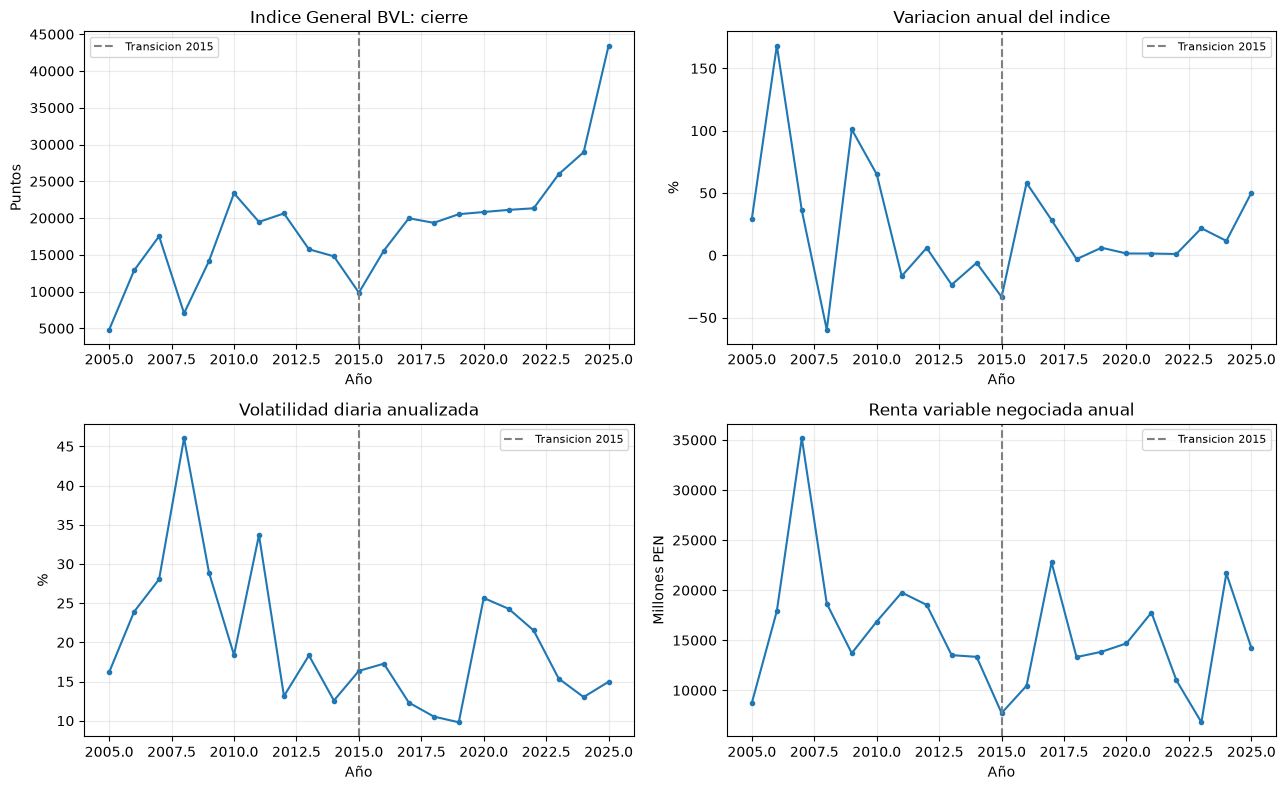

,anio,retornos_validos,retornos_nd,montos_validos,dias_monto_positivo
0,2005,251,9,251,251
1,2006,251,9,251,251
2,2007,251,10,250,250
3,2008,248,14,248,248
4,2009,249,12,250,250
5,2010,251,10,251,251
6,2011,252,8,252,252
7,2012,251,10,251,251
8,2013,250,11,250,250
9,2014,249,12,249,249


In [12]:
fig, axes = plt.subplots(2,2,figsize=(13,8))
for ax,col,title,unidad in zip(axes.flat,["indice_general_cierre","rentabilidad_indice_anual_pct","volatilidad_diaria_anualizada_pct","monto_renta_variable_anual_millones_pen"],
    ["Indice General BVL: cierre","Variacion anual del indice","Volatilidad diaria anualizada","Renta variable negociada anual"],["Puntos","%","%","Millones PEN"]):
    ax.plot(anual.index,anual[col],marker="o",markersize=3)
    ax.axvline(2015,color="gray",linestyle="--",label="Transicion 2015")
    ax.set(title=title,xlabel="Año",ylabel=unidad);ax.legend(fontsize=8)
fig.tight_layout();plt.show()
display(cobertura_mercado[["anio","retornos_validos","retornos_nd","montos_validos","dias_monto_positivo"]])
etapas.append(12)

Los gráficos describen el mercado agregado y no la negociación de una empresa. Los recuentos diarios permiten reconocer cobertura desigual sin sustituir valores faltantes por ceros.

**13. Verificación de cálculos y separación de datasets**

Se recalculan rentabilidad y volatilidad desde registros originales y se contrastan índices anuales y mensuales. Las diferencias se reportan sin corregirlas; se comprueba que ninguna cotización actual se haya incorporado como historia empresarial.

In [13]:
verificacion = []
for anio in ANIOS:
    base = mensual.loc[pd.Timestamp(anio-1,12,1),"indice_general_cierre"]
    cierre = mensual.loc[pd.Timestamp(anio,12,1),"indice_general_cierre"]
    np.testing.assert_allclose(anual.loc[anio,"rentabilidad_indice_anual_pct"],100*(cierre/base-1),rtol=1e-12)
    r=diario.loc[str(anio),"variacion_diaria_indice"].dropna().to_numpy()/100
    if len(r)>=200 and diario.loc[str(anio),"variacion_diaria_indice"].dropna().index.month.nunique()==12:
        log=np.log1p(r); vol=np.sqrt(np.sum((log-log.mean())**2)/(len(log)-1))*np.sqrt(252)*100
        np.testing.assert_allclose(anual.loc[anio,"volatilidad_diaria_anualizada_pct"],vol,rtol=1e-12)
        np.testing.assert_allclose(anual.loc[anio,"retorno_compuesto_observaciones_diarias_pct"],(np.prod(1+r)-1)*100,rtol=1e-10,atol=1e-10)
    verificacion.append({"anio":int(anio),"diferencia_indice_anual_mensual":float(anual.loc[anio,"indice_general_cierre"]-anual.loc[anio,"indice_cierre_publicado_anual"]),
       "diferencia_retornos_pp":float(anual.loc[anio,"diferencia_rentabilidad_pp"]),"diferencia_montos_rv":float(anual.loc[anio,"diferencia_renta_variable_millones_pen"])})
verificacion_calculos=pd.DataFrame(verificacion)
assert anual.index.equals(ANIOS) and not anual.index.duplicated().any()
assert len(cobertura_empresas_anual)==336*21 and not cobertura_empresas_anual.duplicated(["RPJ","anio"]).any()
assert set(empresas.RPJ)==set(empresas_cobertura.RPJ)
assert not instrumentos.cotizacion_asignada_al_panel.any()
assert not instrumentos.duplicated(claves).any()
assert registro.loc[~registro.correspondencia_emisor_verificada,"identidad_instrumento_completa"].eq(False).all()
for anio in ANIOS:
    if diario.loc[str(anio),"monto_acciones_negativo"].any():
        assert pd.isna(anual.loc[anio,"monto_acciones_suma_observaciones_diarias_millones_pen"])
assert empresas_cobertura.loc[empresas_cobertura.accion_registrada,"emisor_identificado"].all()
for info in consultas:
    assert hashlib.sha256((ROOT/info["archivo"]).read_bytes()).hexdigest()==info["sha256"]
assert hashes_protegidos()==hashes_iniciales
assert isin_valido("US0378331005") and not isin_valido("21400100")
assert fecha_bcrp("01.Set.05","D")==pd.Timestamp(2005,9,1)
display(verificacion_calculos.round(6))
print("Verificaciones: formulas, cobertura, identificadores, hashes y archivos anteriores aprobadas.")
etapas.append(13)

,anio,diferencia_indice_anual_mensual,diferencia_retornos_pp,diferencia_montos_rv
0,2005,0.00,-0.000000,0.000000
1,2006,0.00,-1.072541,0.000000
2,2007,0.00,-0.062468,0.590000
3,2008,16.86,-0.000000,0.230000
4,2009,0.00,0.000000,0.000000
5,2010,0.00,-0.000000,0.000000
6,2011,0.00,0.000000,0.000000
7,2012,0.00,-0.000000,0.000000
8,2013,0.00,-0.785484,0.000000
9,2014,0.00,-1.845983,0.000000


Verificaciones: formulas, cobertura, identificadores, hashes y archivos anteriores aprobadas.


Los cálculos se verifican contra los registros de origen, manteniendo visibles las diferencias entre publicaciones. La ausencia de un histórico individual no se reemplaza con la última cotización ni con un índice de mercado.

**14. Exportación y evidencia de ejecución**

Se guardan mercado, registro e instrumentos en archivos separados, junto con cobertura, diccionario y pruebas. Las relecturas verifican integridad numérica y los hashes acreditan que los archivos anteriores permanecen intactos.

In [14]:
assert etapas==list(range(1,14))
definiciones = {
    "anio": ("Año de referencia 2005–2025", "año"),
    "indice_general_cierre": ("PN01142MM, valor de diciembre; base declarada 31/12/91=100", "puntos"),
    "rentabilidad_indice_anual_pct": ("100 * (I_dic_t / I_dic_t_1 - 1), sin imputar ni empalmar variantes", "%"),
    "indice_cierre_publicado_anual": ("PM06338MA anual original; se conserva independiente del cierre mensual", "puntos"),
    "monto_renta_variable_anual_millones_pen": ("PM06345MA anual original; no equivalente estricto a operaciones diarias en acciones", "millones PEN"),
    "capitalizacion_millones_pen": ("PM06348MA anual original", "millones PEN"),
    "monto_renta_variable_suma_meses_millones_pen": ("Suma PN01159MM, requiere 12 meses no faltantes", "millones PEN"),
    "diferencia_renta_variable_millones_pen": ("Suma mensual menos publicacion anual; no se fuerza igualdad", "millones PEN"),
    "n_retornos_diarios": ("Numero de observaciones no n.d. de PD04694MD en el año", "observaciones"),
    "n_meses_con_retornos": ("Numero de meses con alguna observacion de retorno diario", "meses"),
    "volatilidad_diaria_anualizada_pct": ("100 * std(log1p(PD04694MD/100), ddof=1) * sqrt(252); requiere >=200 observaciones y 12 meses", "%"),
    "retorno_compuesto_observaciones_diarias_pct": ("100 * (prod(1 + PD04694MD/100) - 1) sobre datos disponibles; no certifica sesiones completas", "%"),
    "monto_acciones_suma_observaciones_diarias_millones_pen": ("Suma de observaciones PD04696MD con >=200 valores; NaN si algun monto es negativo; no es total anual oficial certificado", "millones PEN"),
    "diferencia_rentabilidad_pp": ("Compuesto diario disponible menos variacion de cierres mensuales", "puntos porcentuales"),
    "transicion_metodologica_2015": ("True en 2015: cambio documentado de calculador/metodologia, sin empalme propio", "booleano"),
    "regimen_documentado": ("Contexto metodologico anterior, de transicion o posterior a mayo 2015", "categoria"),
    "diferencia_diario_mensual_revisar": ("abs(diferencia_rentabilidad_pp) > 0.1; criterio diagnostico fijo, sin uso predictivo", "booleano"),
}
assert set(definiciones) == {"anio", *anual.columns}
diccionario_indicadores = pd.DataFrame([{"variable":k,"transformacion":v[0],"unidad":v[1],
    "disponibilidad":"Conocido solo tras cierre y publicacion; fecha historica y vintage no verificados",
    "alcance":"Mercado agregado; nunca sustituye cotizaciones individuales"} for k,v in definiciones.items()])
# Solo faltantes reales de las tablas, no volumen de negociacion ficticio.
faltantes_mercado = pd.concat([t.isna().sum().rename("faltantes").to_frame().assign(dataset=nombre)
    for nombre,t in [("anual",anual),("mensual",mensual),("diario",diario)]])
faltantes_mercado.index.name="variable"
resumen_instrumentos = pd.DataFrame({"control":["ISIN invalidos en filas originales","Montos inscritos contradictorios por clave","Identidades instrumentales completas"],
    "conteo":[int((~registro.isin_valido).sum()),int(instrumentos.montos_inscritos_distintos.gt(1).sum()),int(instrumentos.identidad_completa.sum())]})
salidas={
    "data/processed/bursatil_mercado_anual.csv":anual.reset_index(),
    "data/processed/bursatil_mercado_mensual.csv":mensual.reset_index(),
    "data/processed/bursatil_mercado_diario.csv":diario.reset_index(),
    "data/processed/bursatil_empresas_cobertura.csv":empresas_cobertura,
    "data/processed/bursatil_registro_smv.csv":registro,
    "data/processed/bursatil_instrumentos_smv.csv":instrumentos,
    "reports/bursatil_cobertura_mercado.csv":cobertura_mercado,
    "reports/bursatil_cobertura_empresas_anual.csv":cobertura_empresas_anual,
    "reports/bursatil_cobertura_instrumentos_anual.csv":cobertura_instrumentos_anual,
    "reports/bursatil_calidad_series.csv":calidad,
    "reports/bursatil_anomalias_montos.csv":anomalias_montos,
    "reports/bursatil_periodos_faltantes.csv":periodos_faltantes,
    "reports/bursatil_consultas_smv.csv":estados_consultas,
    "reports/bursatil_fuentes.csv":fuentes,
    "reports/bursatil_diccionario_series.csv":series,
    "reports/bursatil_diccionario_indicadores.csv":diccionario_indicadores,
    "reports/bursatil_faltantes_mercado.csv":faltantes_mercado.reset_index(),
    "reports/bursatil_calidad_instrumentos.csv":resumen_instrumentos,
    "reports/bursatil_monedas_smv.csv":calidad_monedas,
    "reports/bursatil_verificacion_calculos.csv":verificacion_calculos,
}
inventario={}
for relativo, tabla in salidas.items():
    destino=ROOT/relativo
    tabla.to_csv(destino,index=False,encoding="utf-8",na_rep="")
    inventario[relativo]={"filas":len(tabla),"columnas":len(tabla.columns),"sha256":hashlib.sha256(destino.read_bytes()).hexdigest()}
relectura=pd.read_csv(ROOT/"data/processed/bursatil_mercado_anual.csv",float_precision="round_trip")
pd.testing.assert_frame_equal(relectura.select_dtypes(include="number"),anual.reset_index().select_dtypes(include="number"),check_exact=True,check_dtype=False)
reempresas=pd.read_csv(ROOT/"data/processed/bursatil_empresas_cobertura.csv",dtype={"RPJ":"string","RUC":"string"})
pd.testing.assert_frame_equal(reempresas[["RPJ","RUC"]],empresas_cobertura[["RPJ","RUC"]],check_dtype=False)
assert hashes_protegidos()==hashes_iniciales
manifest={i["archivo"]:i for i in consultas}
manifest_path=RAW/"manifest_bursatil.json"
contenido_manifest=json.dumps(manifest,ensure_ascii=False,indent=2,sort_keys=True)+"\n"
if not manifest_path.exists() or manifest_path.read_text(encoding="utf-8")!=contenido_manifest:
    manifest_path.write_text(contenido_manifest,encoding="utf-8")
validacion={"estado":"COMPLETADO_CON_LIMITACIONES","verificado_utc":datetime.now(timezone.utc).isoformat(),
    "python":platform.python_version(),"versiones":versiones,"mercado_anios":len(anual),"series_bcrp":len(series),
    "empresas_conservadas":len(empresas_cobertura),"emisores_identificados_smv":int(empresas_cobertura.emisor_identificado.sum()),
    "empresas_con_resultados_smv":int(empresas_cobertura.filas_registro_smv.gt(0).sum()),
    "filas_registro_smv":len(registro),"instrumentos_registrales":len(instrumentos),
    "filas_isin_no_validos":int((~registro.isin_valido).sum()),"historicos_individuales_descargados":0,
    "observaciones_diarias_mercado":len(diario),"observaciones_mensuales_mercado_incluida_base":len(mensual),
    "anios_discrepancia_rentabilidad_diaria_mensual":int(anual.diferencia_diario_mensual_revisar.sum()),
    "diferencia_max_indice_anual_mensual_puntos":float(verificacion_calculos.diferencia_indice_anual_mensual.abs().max()),
    "montos_diarios_negativos":len(anomalias_montos),
    "identidades_instrumentales_completas":int(instrumentos.identidad_completa.sum()),
    "cotizaciones_snapshot_fuera_periodo":int(registro.cotizacion_fuera_periodo.sum()),
    "monedas_snapshot":{str(k):int(v) for k,v in registro.Moneda.value_counts(dropna=False).items()},
    "frecuencia_negociacion_individual":"NO_EVALUABLE", "api_bvl_historica":"NO_VERIFICADA",
    "disponibilidad_historica":"NO_VERIFICADA","limitaciones":limitaciones,"salidas":inventario,
    "pruebas":["rentabilidad diciembre/diciembre","volatilidad ddof=1 y sqrt252","composicion diaria por dos formulas", "sin duplicados temporales",
        "336 empresas y 7056 filas de cobertura anual", "ISIN checksum", "n.d. sin imputacion", "relectura CSV exacta", "hash de cada respuesta", "archivos anteriores sin cambios"],
    "archivos_preexistentes_preservados":hashes_iniciales,"ejecucion":{"bloques_codigo":14,"bloques_previos_completados":etapas.copy()},
    "manifest_originales":str(manifest_path.relative_to(ROOT))}
(REPORTS/"validacion_extraccion_bursatil.json").write_text(json.dumps(validacion,ensure_ascii=False,indent=2,allow_nan=False)+"\n",encoding="utf-8")
readme = """# Fuentes bursátiles 2005–2025

Reproducción: ejecutar notebooks/05_extraccion_bursatil.ipynb con el kernel tesis-fcl.
Las versiones de paquetes se registran en reports/validacion_extraccion_bursatil.json.
Con ACTUALIZAR=False se reutilizan los originales verificando sus hashes.
Con True se consultan nuevamente las fuentes y se conservan versiones anteriores.

Los .bin contienen exactamente las respuestas JSON, XML o HTML recibidas.
Cada .meta.json conserva URL, método, solicitud pública, fecha UTC y SHA-256.
manifest_bursatil.json consolida esa trazabilidad; no contiene credenciales.

BCRP: https://estadisticas.bcrp.gob.pe/estadisticas/series/ayuda/api
Condiciones: https://estadisticas.bcrp.gob.pe/estadisticas/series/ayuda/condiciones-de-uso
Atribución: BCRPData; fuentes originales BVL, CAVALI y BCRP según cada serie.

SMV: https://mvnet.smv.gob.pe/SMV.OpenData.Web/Views/Datasets/Valores_Inscritos.aspx
La ficha declara Open Database License (ODbL) 1.0:
https://opendatacommons.org/licenses/odbl/1-0/
Las respuestas y tablas registrales derivadas de SMV se ofrecen bajo esa licencia;
se conserva la atribución a SMV y a Ricardo Villena por la preparación.
La licencia de SMV no se extiende automáticamente a las demás fuentes ni al código.
El SOAP usa la dirección HTTP pública publicada por el WSDL; no envía credenciales.

BVL: https://www.bvl.com.pe/mercado/movimientos-diarios
Se conservaron respuestas públicas de documentación y de su cliente web.
No se verificó una API pública de históricos ni se descargaron series individuales.
No se atribuyen las cotizaciones actuales de SMV a años históricos ni se completan ISIN.

Datasets de mercado y registro están separados en data/processed/.
Diccionarios, controles, cobertura y restricciones se guardan en reports/.
Ningún archivo financiero o macroeconómico anterior participa como salida.
"""
if not (RAW/"README.md").exists() or (RAW/"README.md").read_text(encoding="utf-8") != readme:
    (RAW/"README.md").write_text(readme,encoding="utf-8")
print("Años de mercado:",len(anual),"| Empresas conservadas:",len(empresas_cobertura))
print("Emisores verificados en SMV:",validacion["emisores_identificados_smv"],"| Filas registrales:",len(registro))
print("Historicos individuales descargados:",0,"| Disponibilidad historica no verificada.")
print("Salidas guardadas:",len(salidas),"| Originales y notebooks anteriores intactos.")
etapas.append(14)

Años de mercado: 21 | Empresas conservadas: 336
Emisores verificados en SMV: 154 | Filas registrales: 1032
Historicos individuales descargados: 0 | Disponibilidad historica no verificada.
Salidas guardadas: 20 | Originales y notebooks anteriores intactos.


Se obtienen siete series generales y se conservan 336 empresas: SMV devuelve 1.032 filas para 161 empresas y permite verificar 154 emisores. No se obtuvieron historias individuales; los ISIN recibidos requieren verificación y las discrepancias entre frecuencias quedan reportadas.